# Ansatz - draw


**Sections**
1. **Draw the ansatz** — visualise the circuit for any config.
2. **Routing cost** — star-native vs all-to-all two-qubit-gate scaling (plots).
3. **Pre-flight training** — confirm the model learns above chance 

> The module is device-agnostic: it builds a *logical* circuit for any qubit count `n >= 1`.
> The 5-qubit IQM Spark (ODRA) star is only special because its topology makes the
> `star` entangling pattern *native* (zero SWAP overhead) — see Section 4.

> ⚠️ **Scope: NO error mitigation is applied anywhere in this notebook.**
> Everything runs on a **noiseless** statevector simulator. There is **no noise model** and
> **no QEM** — no ZNE, no Dynamical Decoupling (DD), no Readout Error Mitigation (REM), no
> gate/pulse folding. This notebook only defines the ansatz, measures its routing cost, and
> trains it noiselessly to select a depth. QEM and noise enter later, in the separate
> hardware / noisy-simulator inference pipeline (`plan.md` §7).

In [1]:
import os, pathlib

# Persistent, writable cache for matplotlib + fontconfig. The default ~/.matplotlib and
# ~/.cache are NOT writable on this machine, which makes matplotlib rebuild the font cache
# (~9 s) on every import. Pointing the caches into the project fixes this after one warm-up.
# MUST run before importing matplotlib.
_cache = pathlib.Path.cwd() / ".cache"
(_cache / "mpl").mkdir(parents=True, exist_ok=True)
(_cache / "fontconfig").mkdir(parents=True, exist_ok=True)
os.environ["MPLCONFIGDIR"] = str(_cache / "mpl")
os.environ["XDG_CACHE_HOME"] = str(_cache)   # fontconfig reads $XDG_CACHE_HOME/fontconfig

import numpy as np
import matplotlib.pyplot as plt

from ansatz import (
    HardwareEfficientAnsatz,
    build_ansatz,
    entangling_pairs,
    two_qubit_gate_count,
    ENTANGLEMENT_PATTERNS,
)

print("patterns:", ENTANGLEMENT_PATTERNS)

patterns: ('star', 'all_to_all', 'linear', 'circular')


## 1. Draw the ansatz

Tweak `NUM_QUBITS`, `NUM_LAYERS`, `PATTERN`, `NUM_FEATURES` and re-run. The circuit is drawn below.

pattern=star  qubits=5  layers=1
trainable weights = 25
feature params    = 5
2q entangling gates (logical) = 4
logical depth = 9


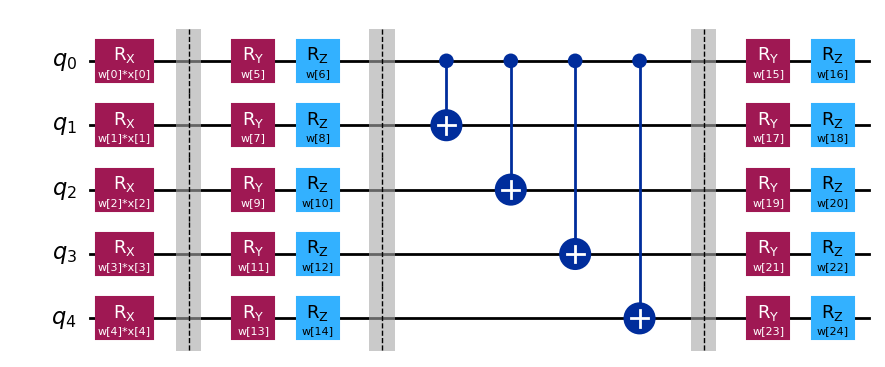

In [2]:
# --- configure the ansatz here -----------------------------------------
NUM_QUBITS   = 5
NUM_LAYERS   = 1
PATTERN      = "star"        # "star" | "all_to_all" | "linear" | "circular"
NUM_FEATURES = None          # None -> defaults to NUM_QUBITS
# -----------------------------------------------------------------------

ansatz = HardwareEfficientAnsatz(
    num_qubits=NUM_QUBITS,
    num_layers=NUM_LAYERS,
    num_features=NUM_FEATURES,
    entanglement=PATTERN,
    insert_barriers=True,   # barriers separate embed / rotate / entangle blocks
)
qc = ansatz.build()

print(f"pattern={PATTERN}  qubits={NUM_QUBITS}  layers={NUM_LAYERS}")
print(f"trainable weights = {ansatz.num_weights}")
print(f"feature params    = {ansatz.num_features}")
print(f"2q entangling gates (logical) = {ansatz.num_entangling_gates}")
print(f"logical depth = {qc.depth()}")

# >>> the ansatz is drawn here <<<
qc.draw("mpl", fold=-1)

## 2. Routing cost — star-native vs all-to-all

The entangling pattern is the study's primary knob. `star` scales as `n-1` two-qubit gates
per layer; `all_to_all` scales as `C(n,2)`. Plot space below.

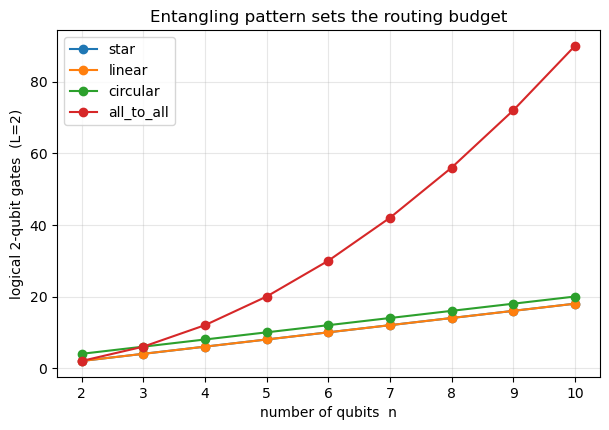

In [3]:
LAYERS = 2
ns = list(range(2, 11))
patterns = ["star", "linear", "circular", "all_to_all"]

counts = {p: [two_qubit_gate_count(build_ansatz(n, LAYERS, entanglement=p)) for n in ns]
          for p in patterns}

fig, ax = plt.subplots(figsize=(7, 4.5))
for p in patterns:
    ax.plot(ns, counts[p], marker="o", label=p)
ax.set_xlabel("number of qubits  n")
ax.set_ylabel(f"logical 2-qubit gates  (L={LAYERS})")
ax.set_title("Entangling pattern sets the routing budget")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## 3. Train on `two_curves` — depth sweep + model selection

Two different "depths" live in this project, with **opposite** roles:

- **Ansatz depth `L`** (number of re-upload / rotate / entangle layers) — a *model*
  hyperparameter you pick. This cell **sweeps `L` over `DEPTHS`** and trains a full VQC at each.
- **Transpiled 2q-gate count** — the *physical* cost the study varies at inference (entangling
  pattern + layout), **without retraining**. That is the routing sweep in Sections 2 / 4.

Workflow: train every depth (Adam + parameter-shift, in the simulator — `plan.md` §5), compare
train/test accuracy vs the logical 2q-gate count, then **lock the depth that classifies best at
the lowest cost**. That single frozen model is what enters the ZNE routing study, so accuracy
changes there are attributable to routing noise and not to a different model.

**Optimizer (fixed):** Adam over parameter-shift gradients
(`∂f/∂θ = [f(θ+π/2) − f(θ−π/2)]/2`) via `TorchConnector` — hardware-faithful, swap the
estimator for hardware and the loop is unchanged.

**Dataset:** `two_curves` (`qml-benchmarks`, arXiv:2403.07059) — see `dataset_specification.md`.

> ⚠️ **No noise and no QEM here.** Training uses a noiseless `StatevectorEstimator` (exact
> expectation values). No ZNE / DD / REM / folding is applied — this is clean model training
> and depth selection only.

The selected (`best_L`) model is **frozen and saved** to `trained_models/` (weights `.npy` +
config `.json`) so the noisy / QEM inference stage reuses the exact same model — never retrained. 

In [4]:
import torch
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split
from qiskit.primitives import StatevectorEstimator
from qiskit.quantum_info import SparsePauliOp
from qiskit_machine_learning.neural_networks import EstimatorQNN
from qiskit_machine_learning.gradients import ParamShiftEstimatorGradient
from qiskit_machine_learning.connectors import TorchConnector

# ---- LOCKED experiment settings (plan.md §6, ODRA Tier A) ----------------
# n_qubits=5 (ODRA star) | re-uploading d=8 onto n=5 | Adam+param-shift
# degree=8/offset=0.3: non-trivial (logreg~0.87 / SVM~0.93). Prefer: python train_vqc.py
N_QUBITS, N_FEATURES = 5, 8
DEPTHS = [2, 3, 4, 5]                 # all depths needed for degree=8 capacity + selection
ENTANGLEMENT = "star"
READOUT = "mean"
N_SAMPLES, DEGREE, OFFSET, NOISE = 150, 8, 0.3, 0.01
EPOCHS, LR, SEED = 60, 0.08, 42
# --------------------------------------------------------------------------

torch.manual_seed(SEED)

# Real generator (required). Install: pip install "git+https://github.com/XanaduAI/qml-benchmarks.git"
from qml_benchmarks.data import generate_two_curves

np.random.seed(SEED)   # generate_two_curves draws from the global RNG
X, y = generate_two_curves(N_SAMPLES, N_FEATURES, degree=DEGREE, offset=OFFSET, noise=NOISE)
y = y.astype(float)                                    # labels already in {-1, +1}
X = MinMaxScaler((-np.pi, np.pi)).fit_transform(X)     # angle range for RX embedding
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=SEED, stratify=y)

Xtr_t = torch.tensor(Xtr, dtype=torch.float32)
ytr_t = torch.tensor(ytr, dtype=torch.float32).view(-1, 1)


def build_qnn(n_layers):
    """HEA at depth `n_layers` wrapped as a parameter-shift EstimatorQNN."""
    vqc = HardwareEfficientAnsatz(
        N_QUBITS, n_layers, num_features=N_FEATURES, entanglement=ENTANGLEMENT
    )
    circ = vqc.build()
    # readout observable (Qiskit Pauli string is ordered qubit-(n-1) ... qubit-0)
    if READOUT == "hub":
        obs = SparsePauliOp.from_list([("I" * (N_QUBITS - 1) + "Z", 1.0)])   # Z on hub (qubit 0)
    elif READOUT == "mean":
        terms = []
        for q in range(N_QUBITS):
            label = ["I"] * N_QUBITS
            label[N_QUBITS - 1 - q] = "Z"
            terms.append(("".join(label), 1.0 / N_QUBITS))                    # (1/n) sum_i Z_i
        obs = SparsePauliOp.from_list(terms)
    else:
        raise ValueError(f"unknown READOUT {READOUT!r}")
    est = StatevectorEstimator()   # NOISELESS simulator: no noise model, no ZNE/DD/REM applied
    qnn = EstimatorQNN(
        circuit=circ, observables=obs,
        input_params=vqc.feature_parameters(circ),
        weight_params=vqc.weight_parameters(circ),
        estimator=est, gradient=ParamShiftEstimatorGradient(est),
    )
    return vqc, qnn


def train(qnn, n_weights):
    """Adam over parameter-shift gradients; returns trained weights + loss history."""
    w0 = 0.1 * np.random.default_rng(SEED).standard_normal(n_weights)
    model = TorchConnector(qnn, initial_weights=w0)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    loss_fn = torch.nn.MSELoss()
    history = []
    for _ in range(EPOCHS):
        optimizer.zero_grad()
        loss = loss_fn(model(Xtr_t), ytr_t)
        loss.backward()
        optimizer.step()
        history.append(loss.item())
    return model.weight.detach().numpy(), history


def accuracy(qnn, w, Xs, ys):
    return float(np.mean(np.sign(qnn.forward(Xs, w).ravel()) == ys))


# ---- train one VQC per depth and compare -----------------------------
runs, results = {}, []
for L in DEPTHS:
    vqc, qnn = build_qnn(L)
    w, history = train(qnn, vqc.num_weights)
    tr = accuracy(qnn, w, Xtr, ytr)
    te = accuracy(qnn, w, Xte, yte)
    runs[L] = {"qnn": qnn, "w": w, "history": history}
    results.append((L, vqc.num_weights, vqc.num_entangling_gates, tr, te))

best_L = max(results, key=lambda r: (r[4], -r[2]))[0]   # best test acc, tie-break: fewer 2q gates

print(f"dataset = two_curves (n={N_SAMPLES}, d={N_FEATURES}, degree={DEGREE}) on "
      f"{N_QUBITS} qubits, entanglement={ENTANGLEMENT}, readout={READOUT}, "
      f"optimizer=Adam(lr={LR})+param-shift, epochs={EPOCHS}, seed={SEED}\n")
print(f"{'depth L':>7} {'weights':>7} {'2q gates':>8} {'train':>7} {'test':>7}")
for L, nw, ng, tr, te in results:
    flag = "  <- best" if L == best_L else ""
    print(f"{L:>7} {nw:>7} {ng:>8} {tr:>7.3f} {te:>7.3f}{flag}")
print(f"\nLock depth L={best_L} for the routing / ZNE study.")

# ---- save the frozen model for the noisy / QEM inference stage --------
import json
import pathlib

best = runs[best_L]
_, best_nw, best_ng, best_tr, best_te = next(r for r in results if r[0] == best_L)
out_dir = pathlib.Path("trained_models")
out_dir.mkdir(exist_ok=True)
tag = f"two_curves_d{N_FEATURES}_q{N_QUBITS}_deg{DEGREE}_{ENTANGLEMENT}_{READOUT}_L{best_L}"

np.save(out_dir / f"{tag}_weights.npy", best["w"])   # order = vqc.weight_parameters(circ)
config = {
    "dataset": "two_curves",
    "n_samples": N_SAMPLES, "n_features": N_FEATURES, "degree": DEGREE,
    "offset": OFFSET, "noise": NOISE, "feature_range": [-float(np.pi), float(np.pi)],
    "n_qubits": N_QUBITS, "n_layers": best_L,
    "entanglement": ENTANGLEMENT, "entangling_gate": "cx",
    "readout": READOUT,
    "observable": "Z on hub qubit 0" if READOUT == "hub" else "(1/n) sum_i Z_i (mean-Z)",
    "num_weights": int(best_nw), "logical_2q_gates": int(best_ng),
    "train_acc": best_tr, "test_acc": best_te,
    "optimizer": f"Adam(lr={LR})+parameter-shift", "epochs": EPOCHS, "seed": SEED,
    "weights_file": f"{tag}_weights.npy",
    "note": "Frozen NOISELESS model. Rebuild with HardwareEfficientAnsatz(n_qubits, n_layers, "
            "num_features, entanglement, entangling_gate) and bind weights in "
            "weight_parameters() order. Apply DD/REM/folding/ZNE at inference only -- do NOT retrain.",
}
with open(out_dir / f"{tag}.json", "w") as f:
    json.dump(config, f, indent=2)

print(f"saved frozen model -> {out_dir / (tag + '.json')}")
print(f"                      {out_dir / (tag + '_weights.npy')}  ({best['w'].shape[0]} weights)")

dataset = two_curves (n=150, d=8, degree=2) on 5 qubits, entanglement=star, readout=mean, optimizer=Adam(lr=0.08)+param-shift, epochs=60, seed=42

depth L weights 2q gates   train    test
      2      40        8   0.981   0.933  <- best
      3      55       12   0.981   0.933

Lock depth L=2 for the routing / ZNE study.
saved frozen model -> trained_models/two_curves_d8_q5_deg2_star_mean_L2.json
                      trained_models/two_curves_d8_q5_deg2_star_mean_L2_weights.npy  (40 weights)


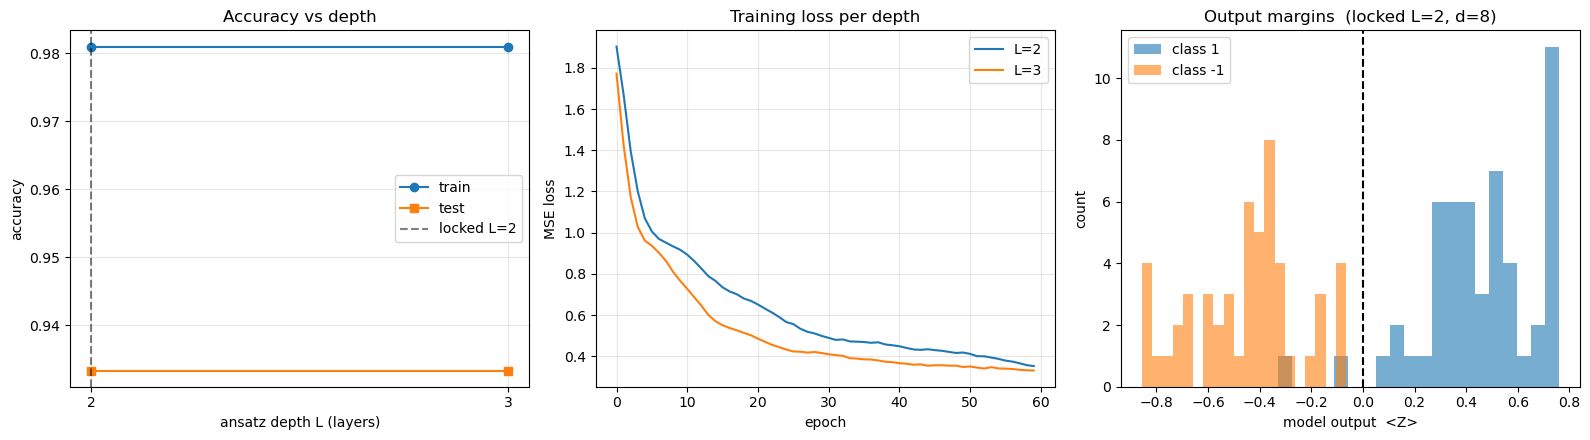

In [5]:
# Plots: accuracy vs depth | loss curves | decision boundary of the selected depth
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

Ls = [r[0] for r in results]
axes[0].plot(Ls, [r[3] for r in results], marker="o", label="train")
axes[0].plot(Ls, [r[4] for r in results], marker="s", label="test")
axes[0].axvline(best_L, color="k", ls="--", alpha=0.5, label=f"locked L={best_L}")
axes[0].set_xlabel("ansatz depth L (layers)")
axes[0].set_ylabel("accuracy")
axes[0].set_title("Accuracy vs depth")
axes[0].set_xticks(Ls)
axes[0].grid(alpha=0.3)
axes[0].legend()

for L in DEPTHS:
    axes[1].plot(runs[L]["history"], label=f"L={L}")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("MSE loss")
axes[1].set_title("Training loss per depth")
axes[1].grid(alpha=0.3)
axes[1].legend()

qnn_b, w_b = runs[best_L]["qnn"], runs[best_L]["w"]
if N_FEATURES == 2:
    g = 60
    xx, yy = np.meshgrid(np.linspace(-np.pi, np.pi, g), np.linspace(-np.pi, np.pi, g))
    zz = qnn_b.forward(np.c_[xx.ravel(), yy.ravel()], w_b).reshape(g, g)
    axes[2].contourf(xx, yy, zz, levels=20, cmap="coolwarm", alpha=0.7)
    axes[2].contour(xx, yy, zz, levels=[0.0], colors="k", linewidths=1.5)
    for lbl, mk in [(1.0, "o"), (-1.0, "s")]:
        m = ytr == lbl
        axes[2].scatter(Xtr[m, 0], Xtr[m, 1], marker=mk, edgecolor="k", label=f"class {int(lbl)}")
    axes[2].set_title(f"Decision boundary (locked L={best_L})")
    axes[2].set_xlabel("feature 0")
    axes[2].set_ylabel("feature 1")
    axes[2].legend()
else:
    # >2 features: no 2-D boundary -> show the model output <Z> separated by class
    out = qnn_b.forward(Xtr, w_b).ravel()
    for lbl, color in [(1.0, "C0"), (-1.0, "C1")]:
        axes[2].hist(out[ytr == lbl], bins=20, alpha=0.6, color=color, label=f"class {int(lbl)}")
    axes[2].axvline(0.0, color="k", ls="--", lw=1.5)
    axes[2].set_title(f"Output margins  (locked L={best_L}, d={N_FEATURES})")
    axes[2].set_xlabel("model output  <Z>")
    axes[2].set_ylabel("count")
    axes[2].legend()

plt.tight_layout()
plt.show()